# Stage 1: geometry-only baseline

This notebook presents a geometry-only baseline for classifying B-rep faces
in the MFCAD dataset. Each face is represented by its surface UV grid and
classified using a shared Face CNN and a two-layer multilayer perceptron.
The aim is to assess the contribution of surface geometry and establish a
reference for later experiments that incorporate graph structure.

The experiment is organised into six sections:

1. [Setup and configuration](#1-setup-and-configuration)
2. [Data pipeline](#2-data-pipeline)
3. [Model](#3-model)
4. [Training pipeline](#4-training-pipeline)
5. [Evaluation pipeline](#5-evaluation-pipeline)
6. [Results and plots](#6-results-and-plots)

We retain the complete official dataset partitions, with the following roles:

| Split | Role in the experiment |
| --- | --- |
| `train` | Parameter optimisation and assessment of the final training fit |
| `validation` | Monitoring loss and accuracy after each epoch and evaluating the final model |
| `test` | Assessing the final model on held-out data |

During training, the evaluation dataset refers to the validation split.
Final performance is reported using the model from the last configured
epoch. Test results are excluded from training and checkpoint selection.
All solids and faces are included, including the final partial batch.

The notebook uses the **gnn_project** kernel, with sections executed in order.

## 1. Setup and configuration

The experiment uses Adam with a learning rate of 0.001, a batch size of
128 solids, and a training duration of 20 epochs. As solids contain different
numbers of faces, the number of classification examples varies between batches.

A fixed random seed and deterministic settings support reproducibility.
Mixed precision is enabled when a CUDA GPU is available. Model checkpoints
and result files are stored in `run_dir`; repeated runs replace files with
the same names.

In [15]:
import csv
import json

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

from uvnet_project.checkpointing import (
    load_training_checkpoint,
    save_training_checkpoint,
    seed_everything,
)
from uvnet_project.classifier import Classifier
from uvnet_project.evaluation import evaluate
from uvnet_project.face_cnn import FaceCNN
from uvnet_project.load_mfcad import DATA_DIR, _load_sample, _load_splits, load_mfcad

In [16]:
# Fix the seed and use the GPU if it is available.
seed = 0
deterministic = True
seed_everything(seed, deterministic=deterministic)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

# Face encoder and classifier sizes.
in_channels = 7
embedding_dim = 64
hidden_dim = 128
num_classes = 16

# Settings for this baseline experiment.
num_epochs = 20
learning_rate = 0.001
batch_size = 128  # solids, not faces
run_dir = DATA_DIR.parent.parent / "results" / "baseline_run_01"

# Leave this as None for a new run, or enter a checkpoint path to resume.
# resume_checkpoint = run_dir / "epoch_010" / "checkpoint.pt"
resume_checkpoint = None

SPLITS = ("train", "validation", "test")
print(f"Device: {device} | mixed precision: {use_amp}")
print(f"Results: {run_dir}")

Device: cuda | mixed precision: True
Results: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\results\baseline_run_01


## 2. Data pipeline

### 2.1 Dataset partitions

Sample IDs are read from the official `split.json` file. We check that each
partition is non-empty, contains unique IDs, and has no overlap with the other
partitions. The original sample order is retained to support the mapping
between saved predictions and their corresponding solids.

In [17]:
official_splits = _load_splits()
split_ids = {}
seen_ids = set()
for split in SPLITS:
    ids = list(official_splits[split])
    if not ids:
        raise ValueError(f"The {split} split is empty.")
    if len(ids) != len(set(ids)):
        raise ValueError(f"Duplicate sample IDs in {split}.")
    overlap = seen_ids.intersection(ids)
    if overlap:
        raise ValueError(f"The {split} split overlaps an earlier split: {sorted(overlap)[:5]}")
    split_ids[split] = ids
    seen_ids.update(ids)

display(pd.DataFrame([
    {"split": split, "solids": len(split_ids[split])}
    for split in SPLITS
]).set_index("split"))
print("All three official splits are non-empty, unique, and disjoint.")

,solids
split,
train,9277
validation,3090
test,3094


All three official splits are non-empty, unique, and disjoint.


### 2.2 Preliminary input checks

Two training solids are loaded using `load_mfcad("train", head=2)` to verify
the input dimensions and label range. This preliminary check does not
restrict the complete datasets used in the
subsequent training and evaluation stages.

In [18]:
samples = load_mfcad("train", head=2)
face_grids = torch.cat([
    sample["graph"].ndata["x"] for sample in samples
]).permute(0, 3, 1, 2).contiguous().float()
labels = torch.tensor([
    face["segment"]["index"]
    for sample in samples
    for face in sample["faces"]
], dtype=torch.long)

print("Face grids:", tuple(face_grids.shape))
print("Labels:", tuple(labels.shape))
assert face_grids.shape[1:] == (in_channels, 10, 10)
assert len(face_grids) == len(labels)
assert labels.min() >= 0 and labels.max() < num_classes

Face grids: (36, 7, 10, 10)
Labels: (36,)


### 2.3 Face representation and preprocessing

The `FaceDataset(split)` class reads all sample IDs in the selected official
partition and loads the graph and aligned face annotations for each solid.

Each face is represented by a 10 x 10 UV grid with seven channels: xyz
coordinates, outward unit normals, and a trimming mask. The coordinates are
supplied in normalised form, and the trimming mask is retained as an input channel.

Grid tensors are rearranged from `(faces, U, V, channels)` to
`(faces, channels, U, V)` for the convolutional layers. Labels are extracted
from the corresponding face annotations. The tensors are cached in RAM,
and the collate function concatenates faces from multiple solids into a batch
while preserving the face order within each solid.

In [19]:
class FaceDataset(Dataset):
    def __init__(self, split):
        self.sample_ids = _load_splits()[split]
        self.samples = []
        # Keep the tensors in RAM so we do not reload them each epoch.
        for sample_id in tqdm(self.sample_ids, desc=f"Cache {split}"):
            sample = _load_sample(sample_id)
            grids = sample["graph"].ndata["x"].permute(0, 3, 1, 2).contiguous().float()
            labels = torch.tensor([face["segment"]["index"]
                                   for face in sample["faces"]], dtype=torch.long)
            self.samples.append((grids, labels))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        return self.samples[index]


def collate_faces(batch):
    grids, labels = zip(*batch)
    return torch.cat(grids), torch.cat(labels)

### 2.4 Dataset caching and batching

The `train_dataset` contains the complete
training split and `evaluation_dataset` contains the complete validation
split. Training batches are shuffled, whereas validation batches retain
the original sample order. Both loaders include the final partial batch.

Existing tensor caches are reused when this cell is rerun in the same
kernel. The test dataset is loaded using the same dataset class during
final evaluation in section 5.

In [20]:
# Reuse the RAM cache when rerunning this cell in the same kernel.
train_dataset = globals().get("train_dataset")
if not hasattr(train_dataset, "samples"):
    train_dataset = FaceDataset("train")
evaluation_dataset = globals().get("evaluation_dataset")
if not hasattr(evaluation_dataset, "samples"):
    evaluation_dataset = FaceDataset("validation")

loader_options = dict(batch_size=batch_size, collate_fn=collate_faces,
                      num_workers=0, pin_memory=use_amp)
train_loader = DataLoader(train_dataset, shuffle=True, **loader_options)
evaluation_loader = DataLoader(evaluation_dataset, shuffle=False, **loader_options)


dataset_summary = pd.DataFrame([
    {
        "split": split,
        "solids": len(dataset),
        "faces": sum(labels.numel() for _, labels in dataset.samples),
    }
    for split, dataset in (("train", train_dataset), ("validation", evaluation_dataset))
]).set_index("split")
display(dataset_summary)

,solids,faces
split,,
train,9277,209847
validation,3090,70255


## 3. Model

### 3.1 Face encoder and classifier

The model encodes each face grid as a 64-dimensional embedding and maps this
embedding to 16 class logits. Faces are classified independently, using
surface geometry without graph adjacency or edge features.

The face encoder follows the UV-Net surface encoder:

`Conv2d(7, 64, 3) -> Conv2d(64, 128, 3) -> Conv2d(128, 256, 3) -> AdaptiveAvgPool2d(1) -> Linear(256, 64)`

The convolutions and final linear projection have no bias and are followed
by batch normalisation and LeakyReLU with a negative slope of 0.01. Padding
of 1 preserves the grid dimensions. Encoder weights use Kaiming uniform
initialisation.

The classifier has the structure `Linear(64, 128) -> ReLU -> Linear(128, 16)`.
The embedding dimension of 64 follows the paper, while the classifier hidden
dimension of 128 is a provisional setting for this experiment. The two-layer
classifier follows the paper's description; the released implementation uses
three linear layers with batch normalisation and dropout.

In [21]:
def build_model():
    face_cnn = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
    classifier = Classifier(
        embedding_dim=embedding_dim, hidden_dim=hidden_dim,
        num_classes=num_classes,
    )
    # Encode each face, then predict its class.
    return nn.Sequential(face_cnn, classifier)


model = build_model().to(device)
print(model)
print("Number of parameters:", sum(p.numel() for p in model.parameters()))

Sequential(
  (0): FaceCNN(
    (conv1): Sequential(
      (0): Conv2d(7, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (conv2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (conv3): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (pool): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc): Sequential(
      (0): Linear(in_features=256, out_features=64, bias=False)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_ru

### 3.2 Forward-pass validation

Before optimisation, the preliminary training batch is passed through the
model to verify the embedding and logit dimensions. We also check that all
logits are finite and that the class probabilities sum to one for each face.
This check uses evaluation mode with gradients disabled, preserving the
model weights and batch-normalisation statistics.

In [22]:
model.eval()
with torch.no_grad():
    embeddings = model[0](face_grids.to(device))
    logits = model[1](embeddings)
    probabilities = torch.softmax(logits, dim=1)

assert embeddings.shape == (len(labels), embedding_dim)
assert logits.shape == (len(labels), num_classes)
assert torch.isfinite(logits).all()
assert torch.allclose(probabilities.sum(dim=1), torch.ones(len(labels), device=device))
print("Face embeddings:", tuple(embeddings.shape))
print("Class logits:", tuple(logits.shape))
print("Forward-pass check passed.")

Face embeddings: (36, 64)
Class logits: (36, 16)
Forward-pass check passed.


## 4. Training pipeline

### 4.1 Optimisation setup and checkpoint restoration

The random seed is reset before model initialisation. Parameters are
optimised using Adam and cross-entropy loss. When resuming a completed
epoch, the model parameters, optimiser state, mixed-precision scaler,
training history, and random states are restored from the checkpoint.
Training settings must match the saved run, although the target number
of epochs may be increased.

Training loss and accuracy are weighted by the number of faces and are
recorded while model parameters change within an epoch. Validation metrics
are calculated at the end of each epoch without parameter updates. Final
evaluation uses float32, so small differences from the mixed-precision
training logs may occur.

In [23]:
run_dir.mkdir(parents=True, exist_ok=True)
if num_epochs < 1:
    raise ValueError("num_epochs must be at least 1.")

seed_everything(seed, deterministic=deterministic)
model = build_model().to(device)
if use_amp:
    model = model.to(memory_format=torch.channels_last)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
loss_fn = nn.CrossEntropyLoss()
history = []
batch_history = []
global_step = 0

run_config = dict(stage="baseline", seed=seed, deterministic=deterministic,
                  in_channels=in_channels, embedding_dim=embedding_dim,
                  hidden_dim=hidden_dim, num_classes=num_classes,
                  learning_rate=learning_rate, batch_size=batch_size,
                  mixed_precision=use_amp, train_sample_ids=train_dataset.sample_ids,
                  validation_sample_ids=evaluation_dataset.sample_ids)
start_epoch = 1
if resume_checkpoint is not None:
    restored = load_training_checkpoint(
        resume_checkpoint, model, optimizer, expected_config=run_config, scaler=scaler,
    )
    start_epoch = restored["epoch"] + 1
    history = restored["history"]
    batch_history = restored["batch_history"]
    global_step = batch_history[-1]["step"] if batch_history else 0
    if num_epochs < start_epoch:
        raise ValueError("Set num_epochs above the completed checkpoint epoch to continue training.")
    print(f"Resuming at epoch {start_epoch}; target is epoch {num_epochs}.")

### 4.2 Batch transfer and validation metrics

The helper functions transfer input tensors and labels to the selected
device and calculate validation loss and accuracy. Only the training
and validation loaders are used during the epoch loop. Validation is
performed in evaluation mode with gradients disabled.

In [24]:
def move_batch(grids, labels):
    grids = grids.to(device, non_blocking=True)
    if use_amp:
        grids = grids.contiguous(memory_format=torch.channels_last)
    return grids, labels.to(device, non_blocking=True)


@torch.no_grad()
def validation_metrics(model, loader):
    model.eval()
    total_loss = torch.zeros((), device=device)
    total_correct = torch.zeros((), device=device, dtype=torch.long)
    total_faces = 0
    for grids, labels in tqdm(loader, desc="Validation", leave=False):
        grids, labels = move_batch(grids, labels)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(grids)
            loss = loss_fn(logits, labels)
        total_loss += loss.detach() * labels.numel()
        total_correct += (logits.argmax(1) == labels).sum()
        total_faces += labels.numel()
    return total_loss.item() / total_faces, total_correct.item() / total_faces

### 4.3 Training procedure and checkpointing

Each epoch uses the complete training split for parameter updates, followed
by evaluation on the complete validation split. A checkpoint is saved under
`epoch_NNN/` after each epoch. Epoch metrics are recorded in `history.csv`,
and individual batch losses are recorded in `batch_loss.csv`.

Checkpoints include the states required to resume training from an epoch
boundary. Executing the following cell starts training; test inference is
performed after the configured training schedule is complete.

In [25]:
for epoch in tqdm(range(start_epoch, num_epochs + 1), desc="Epochs"):
    model.train()
    epoch_losses, epoch_correct, epoch_sizes = [], [], []
    for grids, labels in tqdm(train_loader, desc=f"Epoch {epoch}: training", leave=False):
        grids, labels = move_batch(grids, labels)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(grids)
            loss = loss_fn(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        # Collect batch statistics and copy them to the CPU after the epoch.
        epoch_losses.append(loss.detach())
        epoch_correct.append((logits.detach().argmax(1) == labels).sum())
        epoch_sizes.append(labels.numel())

    losses = torch.stack(epoch_losses).cpu().tolist()
    correct = torch.stack(epoch_correct).sum().item()
    faces = sum(epoch_sizes)
    for batch_index, (batch_loss, count) in enumerate(zip(losses, epoch_sizes), 1):
        global_step += 1
        batch_history.append(dict(step=global_step, epoch=epoch, batch=batch_index,
                                  loss=batch_loss, faces=count))
    train_loss = sum(loss * count for loss, count in zip(losses, epoch_sizes)) / faces
    train_accuracy = correct / faces

    validation_loss, validation_accuracy = validation_metrics(model, evaluation_loader)
    row = dict(epoch=epoch, step=global_step, train_loss=train_loss,
               train_accuracy=train_accuracy, validation_loss=validation_loss,
               validation_accuracy=validation_accuracy)
    history.append(row)
    checkpoint_dir = run_dir / f"epoch_{epoch:03d}"
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    save_training_checkpoint(
        checkpoint_dir / "checkpoint.pt", model, optimizer, epoch=epoch, seed=seed,
        config={**run_config, "num_epochs": num_epochs, "checkpoint_every": 1},
        history=history, batch_history=batch_history, scaler=scaler,
        extra=dict(
            train_sample_ids=train_dataset.sample_ids,
            validation_sample_ids=evaluation_dataset.sample_ids,
            test_sample_ids=split_ids["test"],
        ),
    )
    with (run_dir / "history.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(row))
        writer.writeheader()
        writer.writerows(history)
    tqdm.write(f"Epoch {epoch:02d}/{num_epochs} | train loss {train_loss:.4f}, "
               f"accuracy {train_accuracy:.2%} | validation loss {validation_loss:.4f}, "
               f"accuracy {validation_accuracy:.2%}")
    with (run_dir / "batch_loss.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(batch_history[0]))
        writer.writeheader()
        writer.writerows(batch_history)


print(f"Training complete through epoch {history[-1]['epoch']}. Run final evaluation next.")

Epochs:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1: training:   0%|          | 0/73 [00:00<?, ?it/s]

Validation:   0%|          | 0/25 [00:00<?, ?it/s]

Epoch 01/20 | train loss 1.7822, accuracy 42.43% | validation loss 1.3985, accuracy 50.37%


Epoch 2: training:   0%|          | 0/73 [00:00<?, ?it/s]

Validation:   0%|          | 0/25 [00:00<?, ?it/s]

... (51 outputs left out)

Epoch 19/20 | train loss 0.2821, accuracy 89.49% | validation loss 0.2931, accuracy 89.25%


Epoch 20: training:   0%|          | 0/73 [00:00<?, ?it/s]

Validation:   0%|          | 0/25 [00:00<?, ?it/s]

Epoch 20/20 | train loss 0.2640, accuracy 90.16% | validation loss 0.2897, accuracy 89.29%
Training complete through epoch 20. Run final evaluation next.


## 5. Evaluation pipeline

### Final performance evaluation

After training, the test dataset is loaded using the same dataset class
and cache reuse procedure. The final-epoch model is evaluated on the complete
training, validation, and test splits using identical weights. Evaluation
uses float32 computation, evaluation mode, and disabled gradients.

We report the model from the last configured epoch. Test scores do not
influence training settings or checkpoint selection.

A separate `*_predictions.pt` file is saved for each split. These files
contain loss, accuracy, class probabilities, predictions, labels, and a
confusion matrix. Solid and face indices are also stored to link each
prediction to its source face. Repeating evaluation replaces these files.

In [26]:
if not history or history[-1]["epoch"] != num_epochs:
    raise RuntimeError("Complete the configured training epochs before final evaluation.")

# Load the test split after training, using the same dataset class and cache.
test_dataset = globals().get("test_dataset")
if not hasattr(test_dataset, "samples"):
    test_dataset = FaceDataset("test")
train_evaluation_loader = DataLoader(train_dataset, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_options)

datasets = {
    "train": train_dataset,
    "validation": evaluation_dataset,
    "test": test_dataset,
}
evaluation_loaders = {
    "train": train_evaluation_loader,
    "validation": evaluation_loader,
    "test": test_loader,
}
dataset_summary = pd.DataFrame([
    {
        "split": split,
        "solids": len(datasets[split]),
        "faces": sum(labels.numel() for _, labels in datasets[split].samples),
    }
    for split in SPLITS
]).set_index("split")
display(dataset_summary)

checkpoint_dir = run_dir / f"epoch_{history[-1]['epoch']:03d}"
final_results = {}
for split in SPLITS:
    print(f"Final evaluation: {split}")
    final_results[split] = evaluate(
        model, evaluation_loaders[split],
        checkpoint_dir / f"{split}_predictions.pt",
        device=device, sample_ids=datasets[split].sample_ids, split=split,
    )
    result = final_results[split]
    assert result["sample_ids"] == split_ids[split]
    assert len(result["labels"]) == dataset_summary.loc[split, "faces"]
    print(f"  loss {result['loss']:.4f} | accuracy {result['accuracy']:.2%}")

final_train_results = final_results["train"]
final_validation_results = final_results["validation"]
final_test_results = final_results["test"]
print(f"Saved final predictions for all three splits: {checkpoint_dir}")

,solids,faces
split,,
train,9277,209847
validation,3090,70255
test,3094,69411


Final evaluation: train
  loss 0.2729 | accuracy 89.79%
Final evaluation: validation
  loss 0.2897 | accuracy 89.30%
Final evaluation: test
  loss 0.2870 | accuracy 89.34%
Saved final predictions for all three splits: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\results\baseline_run_01\epoch_020


## 6. Results and plots

### 6.1 Loss curves

Training progress is examined using batch loss, a 20-batch moving average,
and validation loss recorded after each epoch. The moving average reduces
short-term variation in the displayed training curve. Test loss is reported
only during final evaluation.

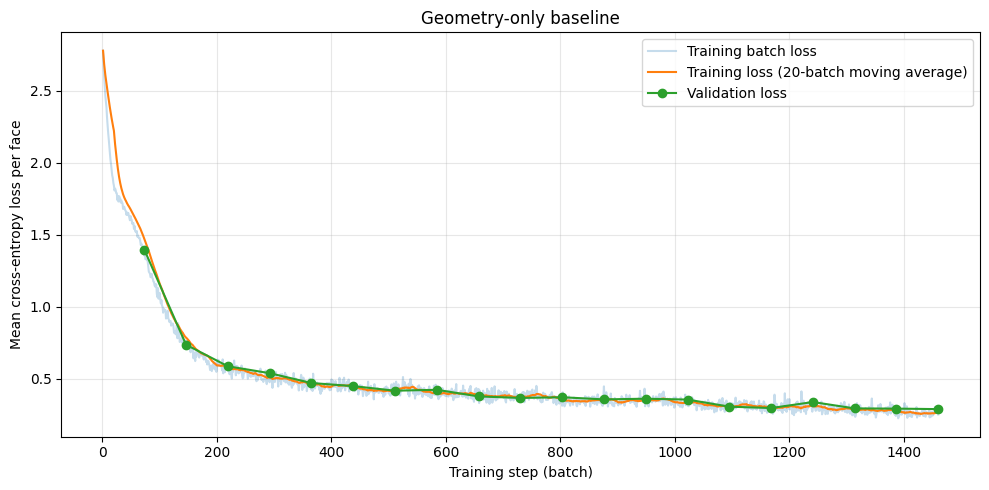

In [27]:
batch_log = pd.DataFrame(batch_history)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(batch_log["step"], batch_log["loss"], alpha=0.25, label="Training batch loss")
ax.plot(batch_log["step"], batch_log["loss"].rolling(20, min_periods=1).mean(),
        label="Training loss (20-batch moving average)")
ax.plot([row["step"] for row in history],
        [row["validation_loss"] for row in history], marker="o", label="Validation loss")
ax.set_xlabel("Training step (batch)")
ax.set_ylabel("Mean cross-entropy loss per face")
ax.set_title("Geometry-only baseline")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(run_dir / "loss.png", dpi=150)
plt.show()

### 6.2 Accuracy and per-class IoU

Accuracy and per-class intersection over union (IoU) are calculated from
the saved predictions for all three splits. For each class, IoU is defined
as `TP / (TP + FP + FN)`, with counts aggregated across all faces in the
selected split. Mean IoU assigns equal weight to each class, includes the
stock class, and excludes classes with zero union.

This analysis reads cached predictions without repeating inference. After
a kernel restart, section 1 provides the imports and configuration needed
to run this cell. The selected epoch is specified by `report_checkpoint_dir`,
and prediction files for all three splits must be available.

In [28]:
# Choose the saved epoch to analyse.
report_checkpoint_dir = run_dir / f"epoch_{num_epochs:03d}"
for split in SPLITS:
    prediction_path = report_checkpoint_dir / f"{split}_predictions.pt"
    if not prediction_path.is_file():
        raise FileNotFoundError(
            f"Missing {prediction_path}. Run final evaluation for all three splits first."
        )

class_names = {}
for label_file in (DATA_DIR / "labels").glob("*.json"):
    with label_file.open() as file:
        faces = json.load(file)["body"]["faces"]
    for face in faces:
        segment = face["segment"]
        class_names[segment["index"]] = segment["name"]
    if len(class_names) == 16:
        break

class_rows = []
summary_rows = []
for split in SPLITS:
    prediction_path = report_checkpoint_dir / f"{split}_predictions.pt"
    results = torch.load(prediction_path, map_location="cpu", weights_only=True)
    labels = results["labels"].long()
    predictions = results["predictions"].long()
    num_classes = results["probabilities"].shape[1]
    confusion = torch.bincount(
        labels * num_classes + predictions, minlength=num_classes**2
    ).reshape(num_classes, num_classes)
    intersection = confusion.diag()
    union = confusion.sum(1) + confusion.sum(0) - intersection
    # Leave out classes with no true or predicted faces when averaging IoU.
    iou = intersection.double() / union.double().masked_fill(union == 0, float("nan"))
    summary_rows.append({
        "split": split,
        "solids": len(results["sample_ids"]),
        "faces": labels.numel(),
        "loss": results["loss"],
        "accuracy": intersection.sum().item() / labels.numel(),
        "mean_iou": iou.nanmean().item(),
    })
    for index in range(num_classes):
        class_rows.append({
            "split": split, "class_index": index,
            "class_name": class_names.get(index, str(index)),
            "support": confusion[index].sum().item(),
            "intersection": intersection[index].item(),
            "union": union[index].item(), "iou": iou[index].item(),
        })

summary = pd.DataFrame(summary_rows).set_index("split")
per_class_iou = pd.DataFrame(class_rows)
display(summary.style.format({"loss": "{:.4f}", "accuracy": "{:.2%}", "mean_iou": "{:.2%}"}))
display(per_class_iou.pivot(index=["class_index", "class_name"],
                           columns="split", values="iou").style.format("{:.2%}"))
summary.to_csv(report_checkpoint_dir / "iou_summary.csv")
per_class_iou.to_csv(report_checkpoint_dir / "per_class_iou.csv", index=False)

,solids,faces,loss,accuracy,mean_iou
split,,,,,
train,9277,209847,0.2729,89.79%,80.46%
validation,3090,70255,0.2897,89.30%,79.45%
test,3094,69411,0.2870,89.34%,79.60%


,split,test,train,validation
class_index,class_name,,,
0,rectangular_through_slot,99.90%,99.86%,99.68%
1,triangular_through_slot,51.64%,53.05%,53.23%
2,rectangular_passage,70.21%,71.98%,70.00%
3,triangular_passage,72.74%,75.81%,76.30%
4,6sides_passage,99.49%,99.79%,99.16%
5,rectangular_through_step,72.26%,73.11%,70.98%
6,2sides_through_step,80.44%,82.20%,80.78%
7,slanted_through_step,96.55%,96.32%,95.51%
8,rectangular_blind_step,93.69%,93.62%,92.00%
